In [1]:
print("My E-Commerce Data Science Project")
print("I am learning by building!")

My E-Commerce Data Science Project
I am learning by building!


In [2]:
import pandas as pd

data = {
    "Product": ["Mouse", "Keyboard", "Headphones"],
    "Brand": ["HP", "Dell", "HP"],
    "Price": [500, 800, 1200],
    "Rating": [4.2, 4.0, 4.5]
}

df = pd.DataFrame(data)

df

,Product,Brand,Price,Rating
0,Mouse,HP,500,4.2
1,Keyboard,Dell,800,4.0
2,Headphones,HP,1200,4.5


In [3]:
df.shape

(3, 4)

In [4]:
df.head()

,Product,Brand,Price,Rating
0,Mouse,HP,500,4.2
1,Keyboard,Dell,800,4.0
2,Headphones,HP,1200,4.5


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3 entries, 0 to 2
Data columns (total 4 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   Product  3 non-null      str    
 1   Brand    3 non-null      str    
 2   Price    3 non-null      int64  
 3   Rating   3 non-null      float64
dtypes: float64(1), int64(1), str(2)
memory usage: 228.0 bytes


In [6]:
df.describe()

,Price,Rating
count,3.000000,3.000000
mean,833.333333,4.233333
std,351.188458,0.251661
min,500.000000,4.000000
25%,650.000000,4.100000
50%,800.000000,4.200000
75%,1000.000000,4.350000
max,1200.000000,4.500000


In [7]:
from selenium import webdriver

driver = webdriver.Chrome()
driver.get("https://books.toscrape.com/")

print(driver.title)

All products | Books to Scrape - Sandbox


In [8]:
from selenium.webdriver.common.by import By
import pandas as pd

# Website par sabhi product cards find karo
products = driver.find_elements(By.CSS_SELECTOR, "article.product_pod")

# Har product se name aur price nikalo
product_data = []

for product in products:
    name = product.find_element(By.CSS_SELECTOR, "h3 a").get_attribute("title")
    price = product.find_element(By.CSS_SELECTOR, ".price_color").text

    product_data.append({
        "Product": name,
        "Price": price
    })

# Data ko table mein badlo
df = pd.DataFrame(product_data)

df

,Product,Price
0,A Light in the Attic,£51.77
1,Tipping the Velvet,£53.74
2,Soumission,£50.10
3,Sharp Objects,£47.82
4,Sapiens: A Brief History of Humankind,£54.23
5,The Requiem Red,£22.65
6,The Dirty Little Secrets of Getting Your Dream...,£33.34
7,The Coming Woman: A Novel Based on the Life of...,£17.93
8,The Boys in the Boat: Nine Americans and Their...,£22.60
9,The Black Maria,£52.15


In [9]:
from pathlib import Path

# Data save karne ke liye folder banao
Path("data").mkdir(exist_ok=True)

# Raw scraped data ko CSV mein save karo
df.to_csv("data/raw_products.csv", index=False)

print("Raw data saved successfully!")

Raw data saved successfully!


In [10]:
import pandas as pd

raw_df = pd.read_csv("data/raw_products.csv")

print("Rows and columns:", raw_df.shape)
raw_df.head()

Rows and columns: (20, 2)


,Product,Price
0,A Light in the Attic,£51.77
1,Tipping the Velvet,£53.74
2,Soumission,£50.10
3,Sharp Objects,£47.82
4,Sapiens: A Brief History of Humankind,£54.23


In [11]:
print(raw_df.head())
print(raw_df.dtypes)

                                 Product   Price
0                   A Light in the Attic  £51.77
1                     Tipping the Velvet  £53.74
2                             Soumission  £50.10
3                          Sharp Objects  £47.82
4  Sapiens: A Brief History of Humankind  £54.23
Product    str
Price      str
dtype: object


In [12]:
import pandas as pd
import numpy as np

# Original data ko safe rakhna
clean_df = raw_df.copy()

# Currency symbol aur extra spaces remove karna
clean_df["Price"] = (
    clean_df["Price"]
    .astype("string")
    .str.replace("£", "", regex=False)
    .str.strip()
)

# Text ko numeric value mein convert karna
clean_df["Price"] = pd.to_numeric(
    clean_df["Price"],
    errors="coerce"
)

clean_df.head()

,Product,Price
0,A Light in the Attic,51.77
1,Tipping the Velvet,53.74
2,Soumission,50.1
3,Sharp Objects,47.82
4,Sapiens: A Brief History of Humankind,54.23


In [13]:
print(clean_df.dtypes)
print("Missing prices:", clean_df["Price"].isna().sum())
print("Duplicate rows:", clean_df.duplicated().sum())

clean_df.head()

Product        str
Price      Float64
dtype: object
Missing prices: 0
Duplicate rows: 0


,Product,Price
0,A Light in the Attic,51.77
1,Tipping the Velvet,53.74
2,Soumission,50.1
3,Sharp Objects,47.82
4,Sapiens: A Brief History of Humankind,54.23


In [14]:
clean_df.to_csv("data/cleaned_products.csv", index=False)

print("Cleaned data saved successfully!")

Cleaned data saved successfully!


In [15]:
import pandas as pd
import numpy as np

# Cleaned dataset load karo
clean_df = pd.read_csv("data/cleaned_products.csv")

print("Dataset size:", clean_df.shape)
print("Total products:", len(clean_df))
print("Missing prices:", clean_df["Price"].isna().sum())
print("Unique prices:", clean_df["Price"].nunique())

Dataset size: (20, 2)
Total products: 20
Missing prices: 0
Unique prices: 20


In [16]:
prices = clean_df["Price"].dropna().to_numpy()

print("Average price:", np.mean(prices))
print("Median price:", np.median(prices))
print("Minimum price:", np.min(prices))
print("Maximum price:", np.max(prices))
print("Standard deviation:", np.std(prices))

Average price: 38.048500000000004
Median price: 41.38
Minimum price: 13.99
Maximum price: 57.25
Standard deviation: 14.751997924010158


In [17]:
valid_df = clean_df.dropna(subset=["Price"])

cheapest = valid_df.loc[valid_df["Price"].idxmin()]
costliest = valid_df.loc[valid_df["Price"].idxmax()]

print("Cheapest book:")
print(cheapest[["Product", "Price"]])

print("\nMost expensive book:")
print(costliest[["Product", "Price"]])

Cheapest book:
Product    Starving Hearts (Triangular Trade Trilogy, #1)
Price                                               13.99
Name: 10, dtype: object

Most expensive book:
Product    Our Band Could Be Your Life: Scenes from the A...
Price                                                  57.25
Name: 15, dtype: object


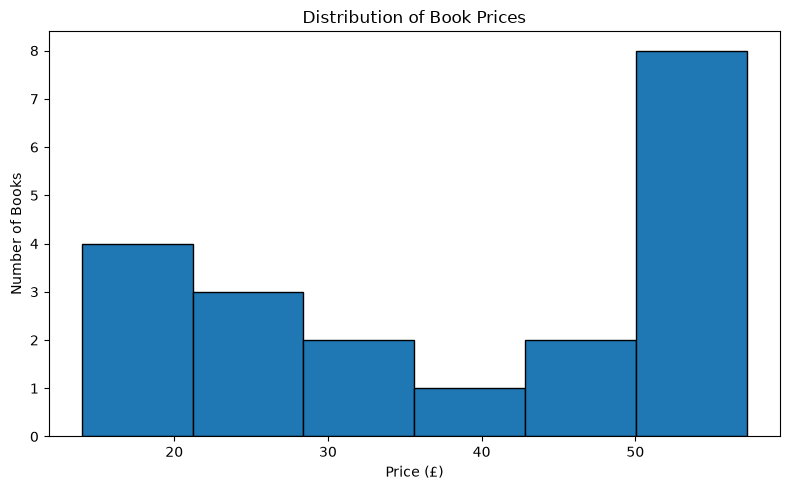

In [18]:
import matplotlib.pyplot as plt

prices = clean_df["Price"].dropna()

plt.figure(figsize=(8, 5))
plt.hist(prices, bins=6, edgecolor="black")

plt.title("Distribution of Book Prices")
plt.xlabel("Price (£)")
plt.ylabel("Number of Books")

plt.tight_layout()
plt.show()

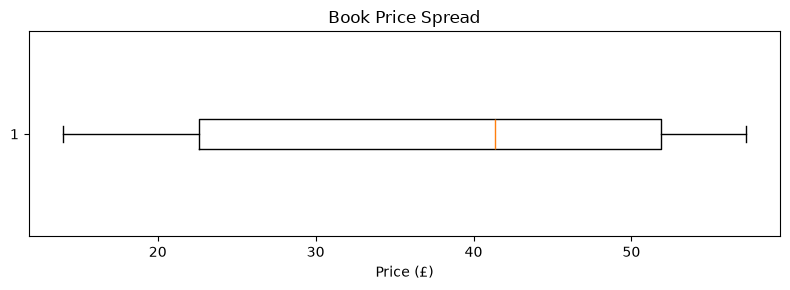

In [20]:
plt.figure(figsize=(8, 3))
plt.boxplot(prices, orientation="horizontal")

plt.title("Book Price Spread")
plt.xlabel("Price (£)")

plt.tight_layout()
plt.show()

In [21]:
from selenium.webdriver.common.by import By

next_button = driver.find_element(
    By.CSS_SELECTOR,
    "li.next a"
)

print("Next page link:", next_button.get_attribute("href"))
print("Button text:", next_button.text)

Next page link: https://books.toscrape.com/catalogue/page-2.html
Button text: next


In [22]:
driver.get("https://books.toscrape.com/")

In [24]:
next_button = driver.find_element(
    By.CSS_SELECTOR, "li.next a"
)

In [25]:
from selenium.webdriver.common.by import By

# Current page par Next link ko dobara find karo
next_url = driver.find_element(
    By.CSS_SELECTOR, "li.next a"
).get_attribute("href")

print("Next page URL:", next_url)

# Next page open karo
driver.get(next_url)

print("Current URL:", driver.current_url)

Next page URL: https://books.toscrape.com/catalogue/page-2.html
Current URL: https://books.toscrape.com/catalogue/page-2.html


In [26]:
driver.get("https://books.toscrape.com/")

In [27]:
from selenium.webdriver.common.by import By
import pandas as pd

products_page2 = driver.find_elements(
    By.CSS_SELECTOR, "article.product_pod"
)

page2_data = []

for product in products_page2:
    name = product.find_element(
        By.CSS_SELECTOR, "h3 a"
    ).get_attribute("title")

    price = product.find_element(
        By.CSS_SELECTOR, ".price_color"
    ).text

    page2_data.append({
        "Product": name,
        "Price": price
    })

df_page2 = pd.DataFrame(page2_data)

print("Products on page 2:", len(df_page2))
df_page2.head()

Products on page 2: 20


,Product,Price
0,A Light in the Attic,£51.77
1,Tipping the Velvet,£53.74
2,Soumission,£50.10
3,Sharp Objects,£47.82
4,Sapiens: A Brief History of Humankind,£54.23


In [28]:
df_combined = pd.concat(
    [df, df_page2],
    ignore_index=True
)

print("Combined dataset shape:", df_combined.shape)
df_combined.head()

Combined dataset shape: (40, 2)


,Product,Price
0,A Light in the Attic,£51.77
1,Tipping the Velvet,£53.74
2,Soumission,£50.10
3,Sharp Objects,£47.82
4,Sapiens: A Brief History of Humankind,£54.23


In [29]:
from selenium.webdriver.common.by import By
import pandas as pd

driver.get("https://books.toscrape.com/")

all_products = []

for page in range(1, 4):
    products = driver.find_elements(
        By.CSS_SELECTOR, "article.product_pod"
    )

    for product in products:
        name = product.find_element(
            By.CSS_SELECTOR, "h3 a"
        ).get_attribute("title")

        price = product.find_element(
            By.CSS_SELECTOR, ".price_color"
        ).text

        all_products.append({
            "Product": name,
            "Price": price
        })

    print(f"Page {page}: {len(products)} products")

    if page < 3:
        next_url = driver.find_element(
            By.CSS_SELECTOR, "li.next a"
        ).get_attribute("href")
        driver.get(next_url)

df_all = pd.DataFrame(all_products)

print("Final dataset shape:", df_all.shape)
df_all.head()

Page 1: 20 products
Page 2: 20 products
Page 3: 20 products
Final dataset shape: (60, 2)


,Product,Price
0,A Light in the Attic,£51.77
1,Tipping the Velvet,£53.74
2,Soumission,£50.10
3,Sharp Objects,£47.82
4,Sapiens: A Brief History of Humankind,£54.23


In [30]:
from pathlib import Path

Path("data").mkdir(exist_ok=True)

df_all.to_csv(
    "data/raw_products_all_pages.csv",
    index=False
)

print("60 products saved successfully!")

60 products saved successfully!


In [31]:
saved_df = pd.read_csv("data/raw_products_all_pages.csv")

print("Dataset shape:", saved_df.shape)
print("Unique product names:", saved_df["Product"].nunique())
print("Missing product names:", saved_df["Product"].isna().sum())

saved_df.tail()

Dataset shape: (60, 2)
Unique product names: 60
Missing product names: 0


,Product,Price
55,The Torch Is Passed: A Harding Family Story,£19.09
56,The Secret of Dreadwillow Carse,£56.13
57,The Pioneer Woman Cooks: Dinnertime: Comfort C...,£56.41
58,The Past Never Ends,£56.50
59,The Natural History of Us (The Fine Art of Pre...,£45.22


In [32]:
print(saved_df.head())
print(saved_df.dtypes)
print(saved_df.isna().sum())

                                 Product   Price
0                   A Light in the Attic  £51.77
1                     Tipping the Velvet  £53.74
2                             Soumission  £50.10
3                          Sharp Objects  £47.82
4  Sapiens: A Brief History of Humankind  £54.23
Product    str
Price      str
dtype: object
Product    0
Price      0
dtype: int64


In [33]:
import pandas as pd
import numpy as np

clean_df = saved_df.copy()

clean_df["Price"] = (
    clean_df["Price"]
    .astype("string")
    .str.replace("£", "", regex=False)
    .str.strip()
)

clean_df["Price"] = pd.to_numeric(
    clean_df["Price"],
    errors="coerce"
)

print(clean_df.dtypes)
print("Missing prices:", clean_df["Price"].isna().sum())

Product        str
Price      Float64
dtype: object
Missing prices: 0


In [34]:
clean_df.to_csv(
    "data/cleaned_products_all_pages.csv",
    index=False
)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


In [35]:
prices = clean_df["Price"].dropna().to_numpy()

print("Total valid prices:", len(prices))
print("Average price:", np.mean(prices))
print("Median price:", np.median(prices))
print("Minimum price:", np.min(prices))
print("Maximum price:", np.max(prices))
print("Standard deviation:", np.std(prices))

Total valid prices: 60
Average price: 35.00266666666667
Median price: 33.485
Minimum price: 12.84
Maximum price: 57.31
Standard deviation: 14.431296992609115


,Metric,Value
0,Total products,60.00
1,Average price,35.00
2,Median price,33.48
3,Minimum price,12.84
4,Maximum price,57.31
5,Missing prices,0.00


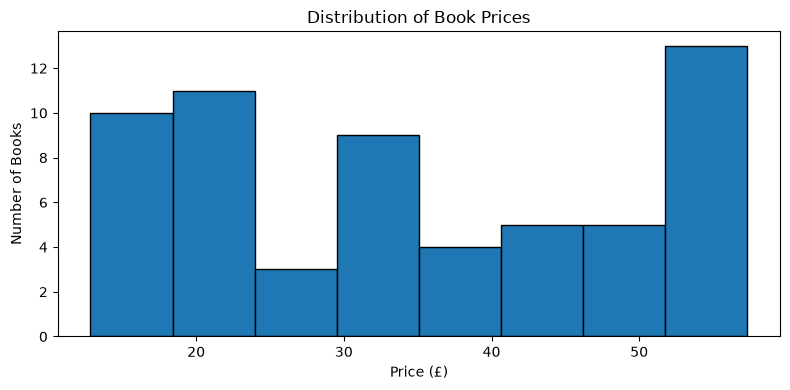

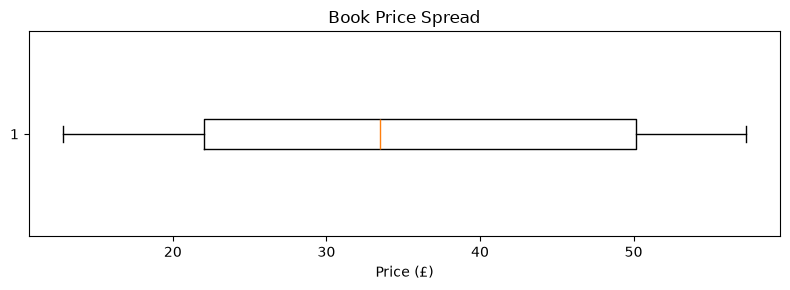

PROJECT ANALYSIS COMPLETE!


In [36]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

prices = clean_df["Price"].dropna()

# Summary report
summary = pd.DataFrame({
    "Metric": [
        "Total products",
        "Average price",
        "Median price",
        "Minimum price",
        "Maximum price",
        "Missing prices"
    ],
    "Value": [
        len(clean_df),
        round(prices.mean(), 2),
        round(prices.median(), 2),
        round(prices.min(), 2),
        round(prices.max(), 2),
        clean_df["Price"].isna().sum()
    ]
})

display(summary)

# Graph 1: Price distribution
plt.figure(figsize=(8, 4))
plt.hist(prices, bins=8, edgecolor="black")
plt.title("Distribution of Book Prices")
plt.xlabel("Price (£)")
plt.ylabel("Number of Books")
plt.tight_layout()
plt.show()

# Graph 2: Price spread
plt.figure(figsize=(8, 3))
plt.boxplot(prices, orientation="horizontal")
plt.title("Book Price Spread")
plt.xlabel("Price (£)")
plt.tight_layout()
plt.show()

# Save final analysis report
summary.to_csv("data/price_analysis_summary.csv", index=False)

print("PROJECT ANALYSIS COMPLETE!")

In [37]:
import pandas as pd

brand_df = pd.read_csv("data/amazon-products.csv")

print("Shape:", brand_df.shape)
print("Columns:", brand_df.columns.tolist())
display(brand_df.head())

FileNotFoundError: [Errno 2] No such file or directory: 'data/amazon-products.csv'

In [38]:
import os

print("Current folder:", os.getcwd())
print("Data folder exists:", os.path.exists("data"))
print("Data folder files:", os.listdir("data") if os.path.exists("data") else "Folder not found")

Current folder: C:\Users\sudha\ecommerce-analysis
Data folder exists: True
Data folder files: ['cleaned_products.csv', 'cleaned_products_all_pages.csv', 'price_analysis_summary.csv', 'raw_products.csv', 'raw_products_all_pages.csv']


In [40]:
import os

print("Current location:", os.getcwd())
print("Project files:")

for root, dirs, files in os.walk("."):
    dirs[:] = [d for d in dirs if d not in ["venv", ".git", "__pycache__"]]
    for file in files:
        if file.lower().endswith(".csv"):
            print(os.path.join(root, file))

Current location: C:\Users\sudha\ecommerce-analysis
Project files:
.\data\cleaned_products.csv
.\data\cleaned_products_all_pages.csv
.\data\price_analysis_summary.csv
.\data\raw_products.csv
.\data\raw_products_all_pages.csv


In [3]:
import pandas as pd

brand_df = pd.read_csv(r"D:\Chrome-Downloads\amazon-products.csv")

print("Dataset shape:", brand_df.shape)
print("Columns:", brand_df.columns.tolist())

display(brand_df.head())

Dataset shape: (1000, 55)
Columns: ['timestamp', 'title', 'seller_name', 'brand', 'description', 'initial_price', 'final_price', 'currency', 'availability', 'reviews_count', 'categories', 'asin', 'buybox_seller', 'number_of_sellers', 'root_bs_rank', 'answered_questions', 'domain', 'images_count', 'url', 'video_count', 'image_url', 'item_weight', 'rating', 'product_dimensions', 'seller_id', 'date_first_available', 'discount', 'model_number', 'manufacturer', 'department', 'plus_content', 'upc', 'video', 'top_review', 'variations', 'delivery', 'features', 'format', 'buybox_prices', 'parent_asin', 'input_asin', 'ingredients', 'origin_url', 'bought_past_month', 'is_available', 'root_bs_category', 'bs_category', 'bs_rank', 'badge', 'subcategory_rank', 'amazon_choice', 'images', 'product_details', 'prices_breakdown', 'country_of_origin']


,timestamp,title,seller_name,brand,description,initial_price,final_price,currency,availability,reviews_count,...,root_bs_category,bs_category,bs_rank,badge,subcategory_rank,amazon_choice,images,product_details,prices_breakdown,country_of_origin
0,2023-08-08 00:00:00.000,Saucony Men's Kinvara 13 Running Shoe,Orv███tor███,Saucony,"When it comes to lightweight speed, nothing cr...",NaN,"""57.79""",USD,In Stock,702,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2023-08-09 00:00:00.000,Kishigo Premium Black Series Heavy Duty Unisex...,Ama███.co███,Kishigo,The Kishigo Premium Black Series Heavy Duty Ve...,NaN,"""28.5""",USD,In Stock,916,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2024-02-04 00:00:00.000,TWINSLUXES Solar Post Cap Lights Outdoor - Wat...,Twi███uxe███,TWINSLUXES,Solar Post Cap Lights Waterproof LED Fence Pos...,"""49.99""","""33.99""",USD,In Stock,3178,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,2024-06-09 00:00:00.000,Accutire MS-4021B Digital Tire Pressure Gauge ...,Cit███ran███Dir██████,Accutire,About this item Heavy duty construction and ru...,1.795000000000000e+01,1.795000000000000e+01,USD,In Stock,8034,...,Automotive,Tire Repair Tools,50.0,NaN,"[{""subcategory_name"":""Automotive"",""subcategory...",False,NaN,NaN,NaN,NaN
4,2024-01-16 00:00:00.000,SAURA LIFE SCIENCE Adivasi Ayurvedic Neelgiri ...,PRA███ EN███PRI███,SAURA LIFE SCIENCE,This extraordinary fusion is designed to nouri...,"""1299""","""799""",INR,In stock,5,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [4]:
# Select important columns
brand_df[["title", "brand", "initial_price", "final_price", "currency"]].info()

# Check missing values
print("\nMissing values:")
print(
    brand_df[["brand", "initial_price", "final_price", "currency"]]
    .isnull()
    .sum()
)

# Check currencies
print("\nCurrency distribution:")
print(brand_df["currency"].value_counts(dropna=False))

# Check most common brands
print("\nTop 15 brands:")
print(brand_df["brand"].value_counts().head(15))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   title          1000 non-null   object
 1   brand          999 non-null    object
 2   initial_price  814 non-null    object
 3   final_price    997 non-null    object
 4   currency       1000 non-null   object
dtypes: object(5)
memory usage: 39.2+ KB

Missing values:
brand              1
initial_price    186
final_price        3
currency           0
dtype: int64

Currency distribution:
currency
USD    967
INR     31
GBP      2
Name: count, dtype: int64

Top 15 brands:
brand
Skechers             11
Amazon Essentials     7
AVERY                 7
New Balance           6
adidas                5
VEVOR                 5
Ambesonne             4
Champion              4
Sperry                3
IRWIN                 3
BOSCH                 3
Propet                3
BDK                   3
Georgia-Pacif

In [5]:
import pandas as pd
import numpy as np

# Original data ko safe rakhna
clean_brand_df = brand_df.copy()

# Missing brand ko remove karna
clean_brand_df = clean_brand_df.dropna(subset=["brand"]).copy()

# Price text se quotes aur extra spaces remove karna
for col in ["initial_price", "final_price"]:
    clean_brand_df[col] = (
        clean_brand_df[col]
        .astype("string")
        .str.replace('"', "", regex=False)
        .str.strip()
    )

    # Price ko numeric format mein convert karna
    clean_brand_df[col] = pd.to_numeric(
        clean_brand_df[col], errors="coerce"
    )

# Final price missing ho toh us row ko remove karna
clean_brand_df = clean_brand_df.dropna(subset=["final_price"]).copy()

print("Original rows:", len(brand_df))
print("Rows after cleaning:", len(clean_brand_df))
print("Missing brands:", clean_brand_df["brand"].isna().sum())
print("Missing final prices:", clean_brand_df["final_price"].isna().sum())

display(
    clean_brand_df[
        ["title", "brand", "initial_price", "final_price", "currency"]
    ].head()
)

Original rows: 1000
Rows after cleaning: 995
Missing brands: 0
Missing final prices: 0


,title,brand,initial_price,final_price,currency
0,Saucony Men's Kinvara 13 Running Shoe,Saucony,<NA>,57.79,USD
1,Kishigo Premium Black Series Heavy Duty Unisex...,Kishigo,<NA>,28.5,USD
2,TWINSLUXES Solar Post Cap Lights Outdoor - Wat...,TWINSLUXES,49.99,33.99,USD
3,Accutire MS-4021B Digital Tire Pressure Gauge ...,Accutire,17.95,17.95,USD
4,SAURA LIFE SCIENCE Adivasi Ayurvedic Neelgiri ...,SAURA LIFE SCIENCE,1299.0,799.0,INR


In [6]:
# Sirf USD products select karo
usd_df = clean_brand_df[
    clean_brand_df["currency"].str.strip().str.upper() == "USD"
].copy()

# Brand-wise product count
brand_counts = (
    usd_df["brand"]
    .value_counts()
    .rename_axis("brand")
    .reset_index(name="product_count")
)

print("USD products:", len(usd_df))
print("Unique brands:", usd_df["brand"].nunique())

print("\nBrands with the most products:")
display(brand_counts.head(15))

USD products: 962
Unique brands: 857

Brands with the most products:


,brand,product_count
0,Skechers,11
1,AVERY,7
2,Amazon Essentials,7
3,New Balance,6
4,adidas,5
5,VEVOR,5
6,Champion,4
7,Ambesonne,4
8,GearIT,3
9,Georgia-Pacific,3


In [7]:
# Aise brands select karo jinke 4 ya usse zyada products hain
eligible_brands = brand_counts.loc[
    brand_counts["product_count"] >= 4, "brand"
].tolist()

print("Eligible brands:", eligible_brands)

# Sirf eligible brands ka data
comparison_df = usd_df[
    usd_df["brand"].isin(eligible_brands)
].copy()

# Har brand ka price summary
brand_summary = (
    comparison_df.groupby("brand")["final_price"]
    .agg(["count", "mean", "median", "min", "max"])
    .round(2)
    .sort_values("mean", ascending=False)
)

display(brand_summary)

Eligible brands: ['Skechers', 'AVERY', 'Amazon Essentials', 'New Balance', 'adidas', 'VEVOR', 'Champion', 'Ambesonne']


,count,mean,median,min,max
brand,,,,,
VEVOR,5,75.94,62.99,28.99,179.99
New Balance,6,64.72,65.03,43.03,87.99
adidas,5,58.9,53.0,32.45,107.0
Skechers,11,52.04,52.35,29.95,75.99
Ambesonne,4,30.46,29.95,24.95,36.99
Champion,4,23.09,23.68,18.25,26.74
AVERY,7,20.32,14.77,10.44,37.87
Amazon Essentials,7,18.03,18.83,12.8,26.32


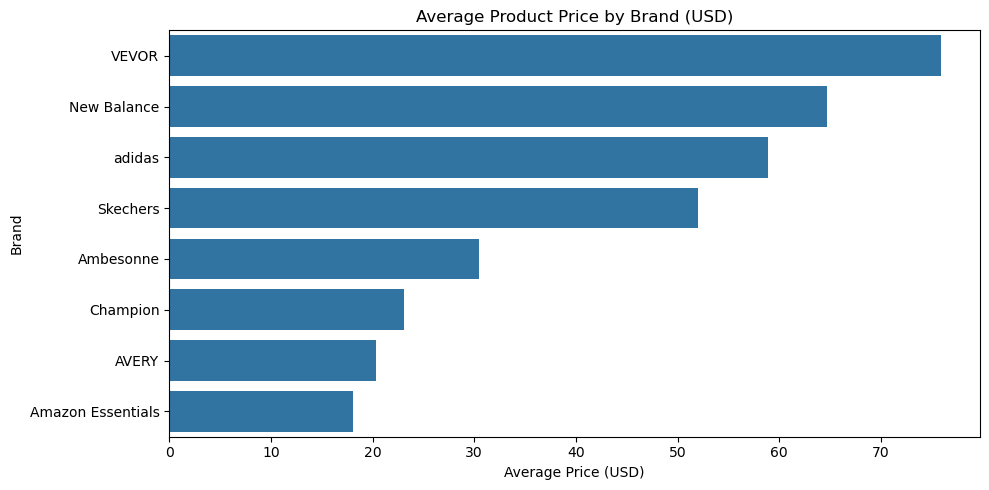

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

# Average price comparison
plt.figure(figsize=(10, 5))

sns.barplot(
    data=brand_summary.reset_index(),
    x="mean",
    y="brand"
)

plt.title("Average Product Price by Brand (USD)")
plt.xlabel("Average Price (USD)")
plt.ylabel("Brand")
plt.tight_layout()
plt.show()

In [9]:
from scipy.stats import ttest_ind

# Dono brands ki prices select karo
skechers = usd_df.loc[
    usd_df["brand"] == "Skechers", "final_price"
]

new_balance = usd_df.loc[
    usd_df["brand"] == "New Balance", "final_price"
]

# Welch's independent two-sample t-test
t_stat, p_value = ttest_ind(
    skechers,
    new_balance,
    equal_var=False
)

print("Skechers sample size:", len(skechers))
print("New Balance sample size:", len(new_balance))
print("Skechers mean price: $", round(skechers.mean(), 2))
print("New Balance mean price: $", round(new_balance.mean(), 2))
print("T-statistic:", round(t_stat, 4))
print("P-value:", round(p_value, 4))

if p_value < 0.05:
    print("Result: Statistically significant difference detected.")
else:
    print("Result: Insufficient evidence of a statistically significant difference.")

Skechers sample size: 11
New Balance sample size: 6
Skechers mean price: $ 52.04
New Balance mean price: $ 64.71
T-statistic: -1.715
P-value: 0.119
Result: Insufficient evidence of a statistically significant difference.


In [10]:
import os
import pandas as pd

os.makedirs("data", exist_ok=True)

test_result = pd.DataFrame([{
    "Brand 1": "Skechers",
    "Brand 2": "New Balance",
    "Sample Size 1": len(skechers),
    "Sample Size 2": len(new_balance),
    "Mean Price 1 (USD)": round(skechers.mean(), 2),
    "Mean Price 2 (USD)": round(new_balance.mean(), 2),
    "T-statistic": round(t_stat, 4),
    "P-value": round(p_value, 4),
    "Significance Level": 0.05,
    "Conclusion": "Insufficient evidence of a significant difference"
}])

test_result.to_csv("data/hypothesis_test_results.csv", index=False)

display(test_result)
print("Hypothesis test result saved successfully!")

,Brand 1,Brand 2,Sample Size 1,Sample Size 2,Mean Price 1 (USD),Mean Price 2 (USD),T-statistic,P-value,Significance Level,Conclusion
0,Skechers,New Balance,11,6,52.04,64.71,-1.715,0.119,0.05,Insufficient evidence of a significant difference


Hypothesis test result saved successfully!


# E-Commerce Product Price Analysis and Brand Comparison

## Project Objective

The objective of this project is to collect, clean, and analyze product price data using Python. It explores price distributions, compares average prices across selected brands, and applies statistical hypothesis testing to assess whether the observed difference in mean prices between two brands is statistically significant.

## Tools and Technologies

- Python
- Pandas and NumPy
- Selenium
- Matplotlib and Seaborn
- SciPy
- Jupyter Notebook

## Key Questions

1. What is the distribution of product prices?
2. How do average prices vary across selected brands?
3. Is the observed difference in mean prices between Skechers and New Balance statistically significant?
4. What are the limitations of the analysis?



In [11]:
import pandas as pd

brand_df = pd.read_csv(r"D:\Chrome-Downloads\amazon-products.csv")

print("Dataset shape:", brand_df.shape)

Dataset shape: (1000, 55)


In [12]:
brand_df = pd.read_csv("data/amazon-products.csv")

In [13]:
print(brand_df.shape)

(1000, 55)


In [14]:
import pandas as pd

brand_df = pd.read_csv("data/amazon-products.csv")

print("Dataset shape:", brand_df.shape)

Dataset shape: (1000, 55)
